<a href="https://colab.research.google.com/github/potopinc/colab/blob/main/ML_13_14.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Часть 1 (Занятие 13). Задача кластеризации. Метод k-means

## Импорт библиотек

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.datasets import make_blobs

## Создаем данные

In [2]:
X, _ = make_blobs(n_samples=300, centers=4, cluster_std=1.0, random_state=21)

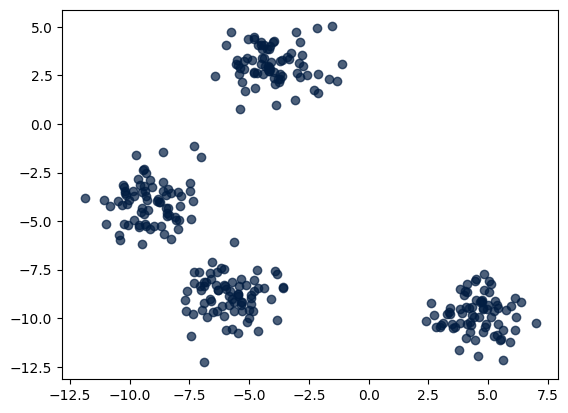

In [3]:
plt.scatter(X[:, 0], X[:, 1], c='#011d42', alpha=0.7);

## Реализуем Kmeans

Необходимо выполнить имплементацию следующих методов:
- `find_center(self, cl, s)` возвращает центр кластера, у которого `s` измерений;
- `fit_predict(self, X)` возвращает `predictions` (предсказания) и `centers_` центры кластеров.

In [4]:
class Custom_KMeans:
    def __init__(self, k, max_iter, seed):

        self.seed = np.random.seed(seed)  # Фиксируем seed для воспроизводимости
        self.k = k  # Количество кластеров
        self.max_iter = max_iter  # Макс. число итераций
        self.clusters = None  # Будет хранить списки точек каждого кластера
        self.centers = None  # Будет хранить центроиды кластеров

    def distance(self, x1, x2):
        return (sum((x1 - x2) ** 2)) ** 0.5

    def find_center(self, cl, s):
        min_dis = 10 ** 20
        center = np.random.rand(5)

        for point_1 in cl:
          sum_d = sum([self.distance(point_1, point_2) for point_2 in cl])
          if sum_d < min_dis:
            min_dis = sum_d
            center = point_1
        return center
    def fit_predict(self, X):
        self.centers = np.random.uniform(X.min(), X.max(), size=(self.k, X.shape[1]))

        for _ in range(self.max_iter):
          predictions = []
          self.clusters = [[] for _ in range(self.k)]

          for obj in X:
            distances = np.array([self.distance(obj, center) for center in self.centers])
            self.clusters[distances.argmin()].append(obj) #добав точку в кластер
            predictions.append(distances.argmin()) #замониаем метку кластера
            # print(distances.argmin())

          centers_ = self.centers
          self.centers = np.array([self.find_center(cl, X.shape[1]) for cl in self.clusters])

        return np.array(predictions), centers_ # метки, центроиды


Проверка

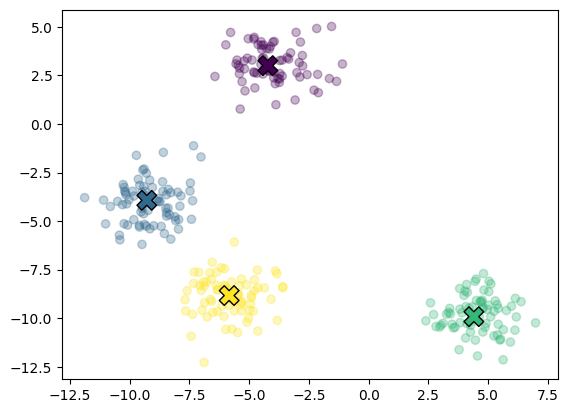

In [5]:
km = Custom_KMeans(k = 4, max_iter=10, seed = 1)
preds, centers_ = km.fit_predict(X)
plt.scatter(X[:, 0], X[:, 1], c=preds, alpha=0.3);
plt.scatter(centers_[:, 0], centers_[:, 1], c = [0, 1, 2, 3], marker='X', edgecolor='black', s = 200);

**K-means++**

Это дополнительное задание. Реализуй начальный выбор центров кластеров по следующему алгоритму:

- Выбери первый центроид случайно из всех точек.
- Для каждой оставшейся точки вычисли расстояние до ближайшего уже выбранного центроида. Важно: чем дальше точка от существующих центроидов, тем выше вероятность её выбора.
- Выбери следующий центроид случайно, но с вероятностью, пропорциональной квадрату расстояния.
- Повторяем, пока не выберешь все k центроидов.

## Решаем 27-ю задачу из ЕГЭ

Суть этой задачи сводится к поиску центров кластеров.

Сами кластеры могут быть различной формы, иметь шумовые точки, но легко различимы для человека.

In [6]:
def data(path):
  with open(path) as f:
    return np.array([list(map(float, line.replace(',', '.').split())) for line in f.readlines()])

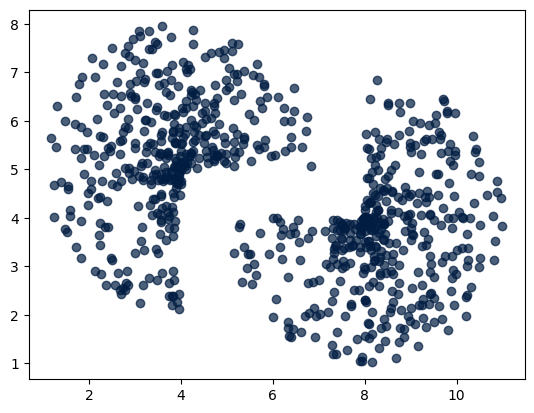

In [9]:
X = data('27-92a.txt')
plt.scatter(X[:, 0], X[:, 1], c='#011d42', alpha=0.7)

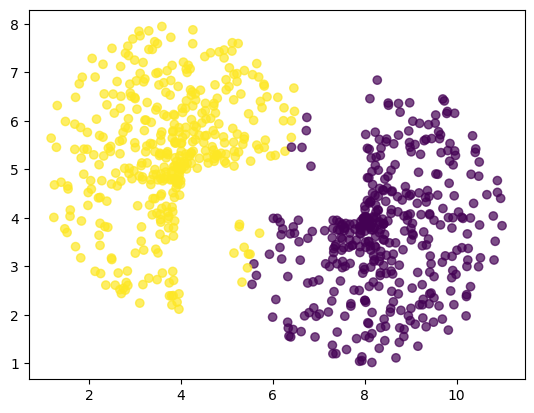

In [10]:
km = Custom_KMeans(k=2, max_iter = 10, seed=1)
preds, centers_ = km.fit_predict(X)
plt.scatter(X[:, 0], X[:, 1], c=preds, alpha=0.7)

Сравним с `sklearn`.

In [11]:
from sklearn.cluster import KMeans

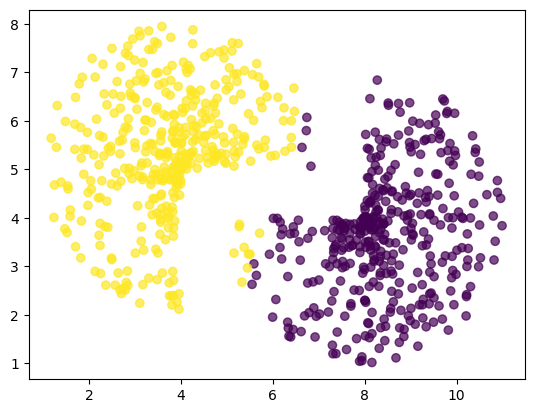

In [12]:
preds = KMeans(n_clusters=2).fit_predict(X)
plt.scatter(X[:, 0], X[:, 1], c=preds, alpha=0.7)

Попробуем другие данные

## Тестируем на многомерных данных

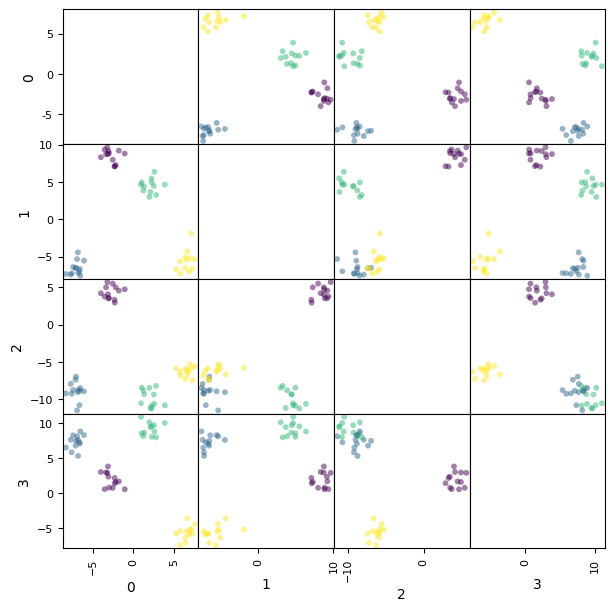

In [13]:
X, y = make_blobs(n_samples=50, centers=4, n_features=4, cluster_std=1, random_state=42)
pd.plotting.scatter_matrix(pd.DataFrame(X), c=y, s=70, figsize=(7,7), diagonal=None);

In [14]:
km = Custom_KMeans(k=4, max_iter=10, seed=1)
preds, centers_ = km.fit_predict(X)

In [15]:
print(*preds[:20].tolist())
print(*y[:20])

3 3 0 1 2 2 3 1 1 1 1 2 3 2 3 0 0 0 0 2
2 2 3 1 0 0 2 1 1 1 1 0 2 0 2 3 3 3 3 0


In [16]:
from sklearn.metrics import adjusted_mutual_info_score

In [17]:
print(adjusted_mutual_info_score(y, preds))

1.0


## Считаем силуэт

Для задач ЕГЭ сделайте предсказани,я используя `KMeans` из sklearn, и посчитайте `silhouette_score`

In [18]:
from sklearn.metrics import silhouette_score

In [19]:
X = data('27-91a.txt')
preds = KMeans(n_clusters=2).fit_predict(X)

In [20]:
print(silhouette_score(X, preds))

0.6567260509823137


# Часть 2 (Занятие 14). Задача кластеризации. Метод DBSCAN. Понижение размерности

## Импорт библиотек

In [21]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.datasets import make_blobs
from sklearn.cluster import DBSCAN, KMeans
from sklearn.metrics import adjusted_mutual_info_score, silhouette_score

## Тестируем DBSCAN на задачах из ЕГЭ

In [22]:
def data(path):
  with open(path) as f:
    return np.array([list(map(float, line.replace(',', '.').split())) for line in f.readlines()])

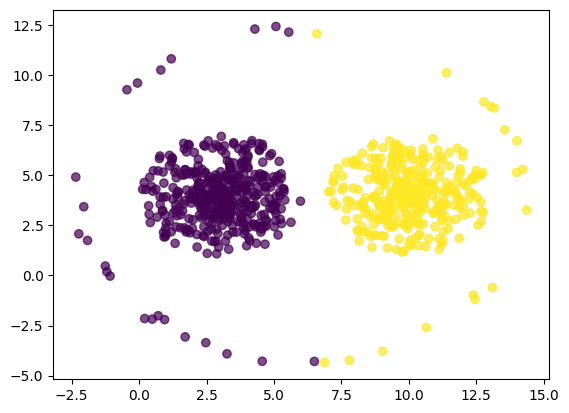

In [23]:
X = data('27-91a.txt')
plt.scatter(X[:, 0], X[:, 1], c=preds, alpha=0.7)

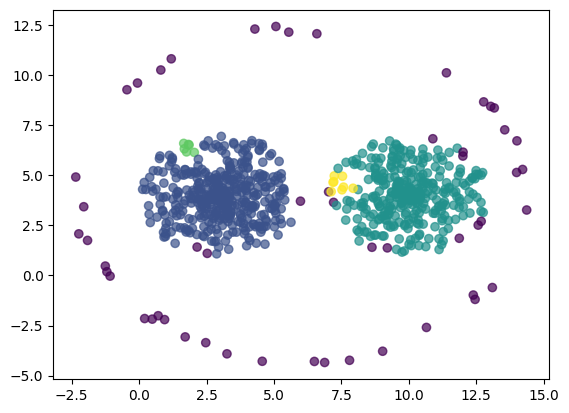

In [24]:
preds = DBSCAN().fit_predict(X)
plt.scatter(X[:, 0], X[:, 1], c=preds, alpha=0.7)

#### **Задание 1**

Для файла `27-68b.txt` добейтесь наилучшего разбиения на кластеры используя `DBSCAN`.

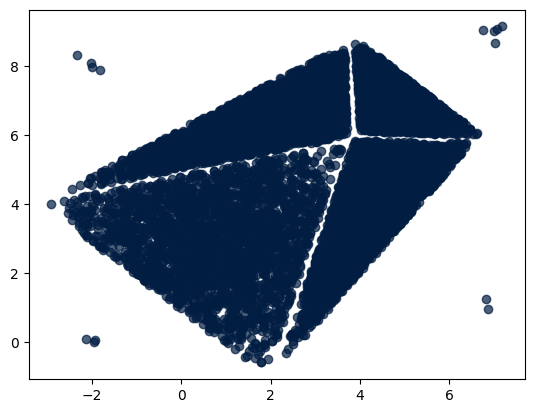

In [25]:
X = data('27-68b.txt')
plt.scatter(X[:, 0], X[:, 1], c='#011d42', alpha=0.7)

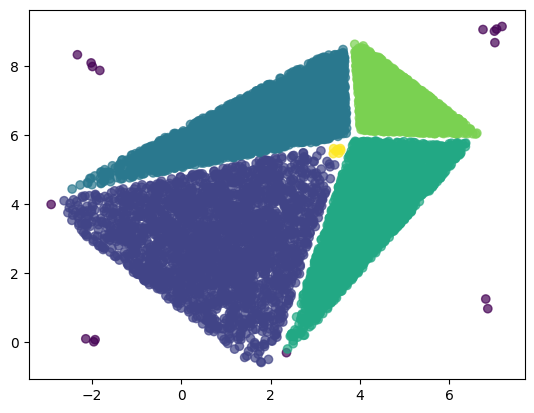

In [26]:
preds = DBSCAN(eps=0.215, min_samples=4).fit_predict(X)
plt.scatter(X[:, 0], X[:, 1], c=preds, alpha=0.7)

#### **Задание 2**

Используйте `KMeans` на данных из задания 1.

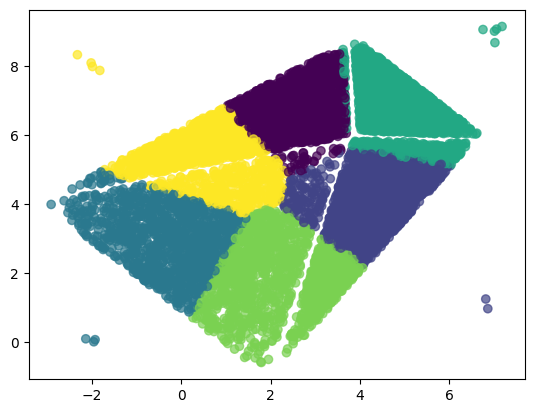

In [27]:
preds = KMeans(n_clusters=6).fit_predict(X)
plt.scatter(X[:, 0], X[:, 1], c=preds, alpha=0.7)

## Метод главных компонент

Используя `PCA`, сократите размерность данных до 2. Визуализируйте результат.

Обучите `KMeans` для данных сниженной размерности до 2 и 3. Сравните результат по метрике `adjusted_mutual_info_score`

In [28]:
from sklearn.decomposition import PCA

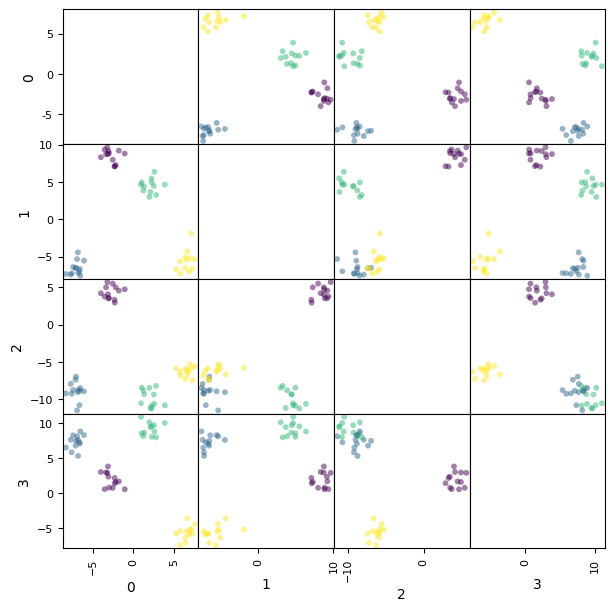

In [29]:
X, y = make_blobs(n_samples=50, centers=4, n_features=4, cluster_std=1, random_state=42)
pd.plotting.scatter_matrix(pd.DataFrame(X), c=y, s=70, figsize=(7,7), diagonal=None);

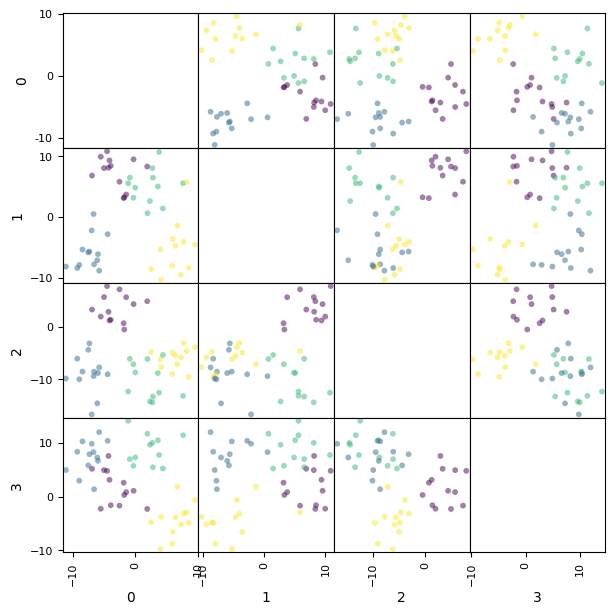

In [30]:
X, y = make_blobs(n_samples=50, centers=4, n_features=4, cluster_std=3, random_state=42)
pd.plotting.scatter_matrix(pd.DataFrame(X), c=y, s=70, figsize=(7,7), diagonal=None);

<BarContainer object of 4 artists>

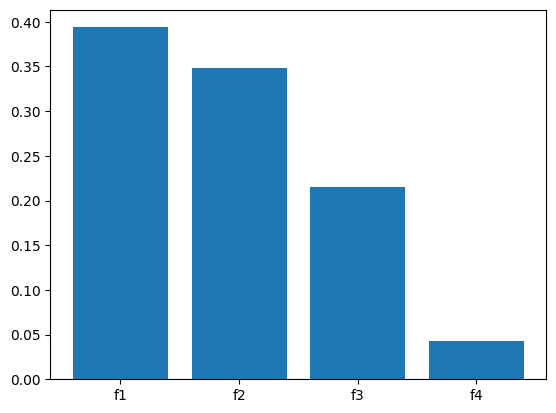

In [31]:
pca = PCA(n_components=4)
new_X = pca.fit_transform(X)
plt.bar(['f1', 'f2', 'f3', 'f4'], pca.explained_variance_ratio_)

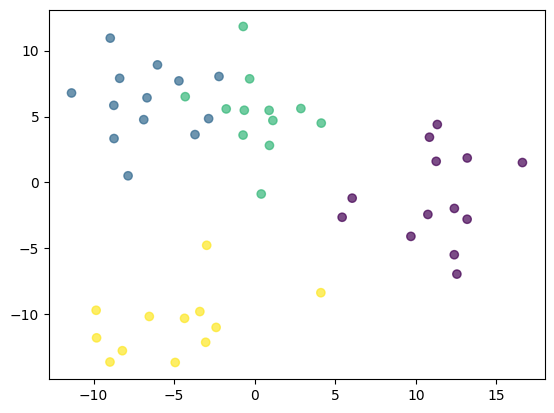

In [32]:
pca = PCA(n_components=2)
new_X = pca.fit_transform(X)
plt.scatter(new_X[:, 0], new_X[:, 1], c=y, alpha=0.7)

In [33]:
adjusted_mutual_info_score(y, KMeans(n_clusters=4).fit_predict(X))

np.float64(0.9999999999999998)

In [34]:
adjusted_mutual_info_score(y, KMeans(n_clusters=4).fit_predict(new_X))

np.float64(0.7803900473146416)

In [35]:
new_X_2 = PCA(n_components=3).fit_transform(X)

In [36]:
adjusted_mutual_info_score(y, KMeans(n_clusters=4).fit_predict(new_X_2))

np.float64(1.0)

## Практика

Вам предстоит решить задачу кластеризации. Про данные ничего неизвестно, правильных ответов нет.

In [37]:
X = pd.read_csv('data.csv')
X

,0,1,2,3,4,5,6,7,8,9,...,54,55,56,57,58,59,60,61,62,63
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,11.0,16.0,10.0,0.0,0.0
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,0.0,0.0,0.0,...,5.0,0.0,0.0,0.0,0.0,3.0,11.0,16.0,9.0,0.0
3,0.0,0.0,7.0,15.0,13.0,1.0,0.0,0.0,0.0,8.0,...,9.0,0.0,0.0,0.0,7.0,13.0,13.0,9.0,0.0,0.0
4,0.0,0.0,0.0,1.0,11.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,2.0,16.0,4.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1792,0.0,0.0,4.0,10.0,13.0,6.0,0.0,0.0,0.0,1.0,...,4.0,0.0,0.0,0.0,2.0,14.0,15.0,9.0,0.0,0.0
1793,0.0,0.0,6.0,16.0,13.0,11.0,1.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,6.0,16.0,14.0,6.0,0.0,0.0
1794,0.0,0.0,1.0,11.0,15.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,2.0,9.0,13.0,6.0,0.0,0.0
1795,0.0,0.0,2.0,10.0,7.0,0.0,0.0,0.0,0.0,0.0,...,2.0,0.0,0.0,0.0,5.0,12.0,16.0,12.0,0.0,0.0


#### **Задание 1**

Уменьшите размерность до двух осей и визуализируйте данные, чтобы понять, с чем предстоит работать.

Для визуализации задайте размер фигуры 10x10.

Ниже напишите свое предположение о количестве кластеров.

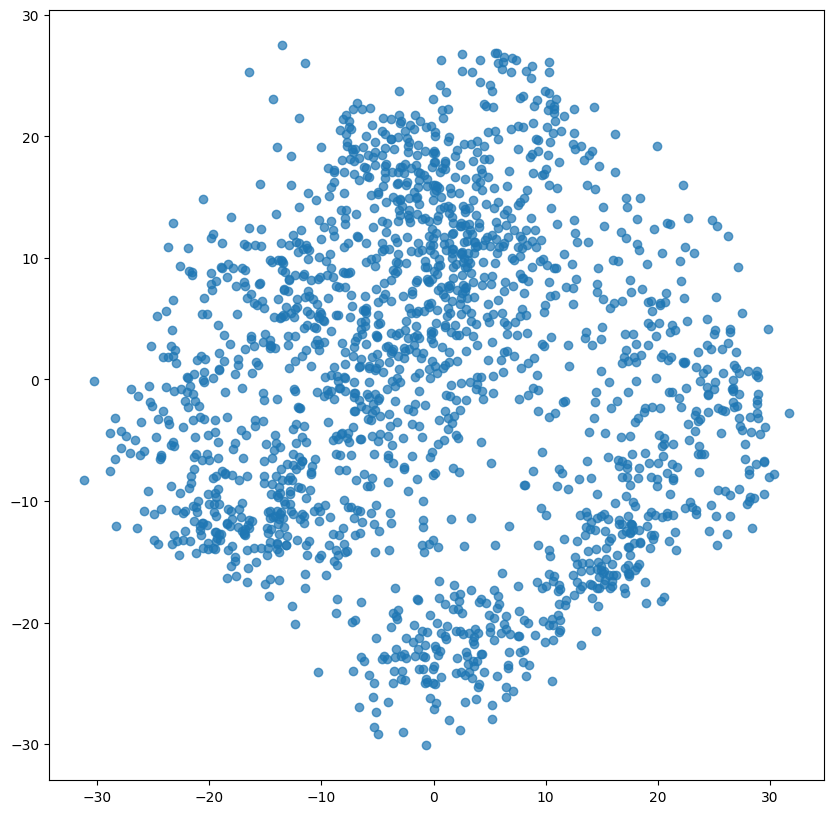

In [38]:
pca = PCA(n_components=2)
new_X = pca.fit_transform(X)
plt.figure(figsize=(10, 10))
plt.scatter(new_X[:, 0], new_X[:, 1], alpha=0.7)

Я думаю, что здесь 3 кластеров.

#### **Задание 2**

Используйте PCA. До какого количества признаков можно сократить размерность? Какой процент дисперсии удастся сохранить? Постройте график.

29 из 64
95.47965245651596


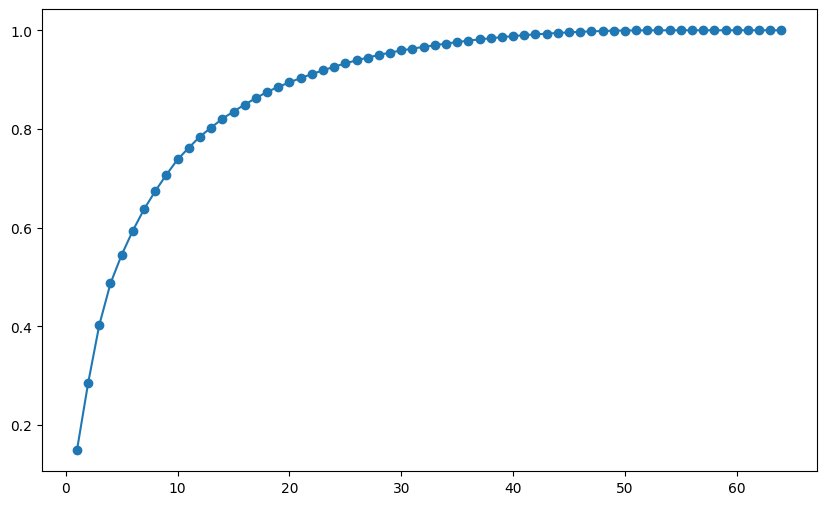

In [39]:
pca = PCA()
pca.fit(X)

cum_var = np.cumsum(pca.explained_variance_ratio_)
# print(X)
# print(pca.explained_variance_ratio_)
# print(cum_var)

plt.figure(figsize=(10, 6))
plt.plot([i for i in range(1, len(cum_var) + 1)], cum_var, marker='o')

n = np.argmax(cum_var >= 0.95) + 1

print(n, 'из', X.shape[1])
print(cum_var[n - 1] * 100)

#### **Задание 3**

Сравните KMeans с базовыми параметрами и DBSCAN с параметром `eps = 20` по метрике silhouette_score.

Используйте данные без понижения размерности.

In [43]:
print(silhouette_score(X, KMeans().fit_predict(X)))

0.17598808153112197


In [44]:
print(silhouette_score(X, DBSCAN(eps=20).fit_predict(X)))

0.06949380671387066


#### **Задание 4**

Визуализируйте ответы `KMeans` и `DBSCAN` из прошлого задания на данных сниженной размерности из задания 1.

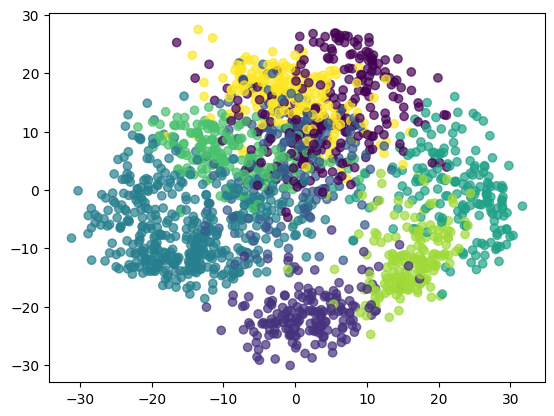

In [45]:
preds = KMeans().fit_predict(X)
plt.scatter(new_X[:, 0], new_X[:, 1], c=preds, alpha=0.7)

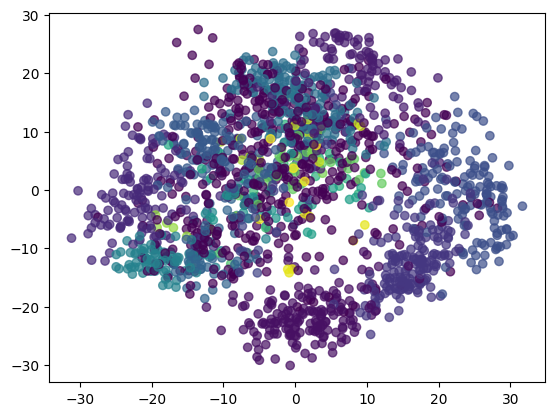

In [46]:
preds = DBSCAN(eps=20).fit_predict(X)
plt.scatter(new_X[:, 0], new_X[:, 1], c=preds, alpha=0.7)

#### **Задание 5**

При каком количестве кластеров KMeans даёт наилучший результат?

Для лучшего параметра `n_clusters` визуализируйте предсказания на данных сниженной размерности.

Минимальное количество кластеров — 2.

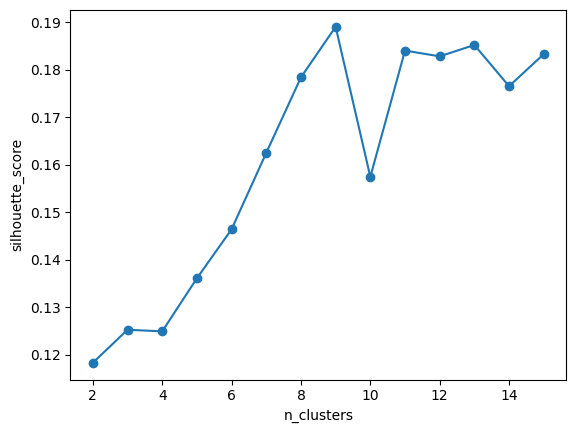

9 0.18906930646858977


In [47]:
scores = []
for k in range(2, 16):
    preds = KMeans(n_clusters=k).fit_predict(X)
    scores.append(silhouette_score(X, preds))

plt.plot(range(2, 16), scores, marker='o')
plt.xlabel('n_clusters')
plt.ylabel('silhouette_score')
plt.show()

best_k = np.argmax(scores) + 2
print(best_k, max(scores))

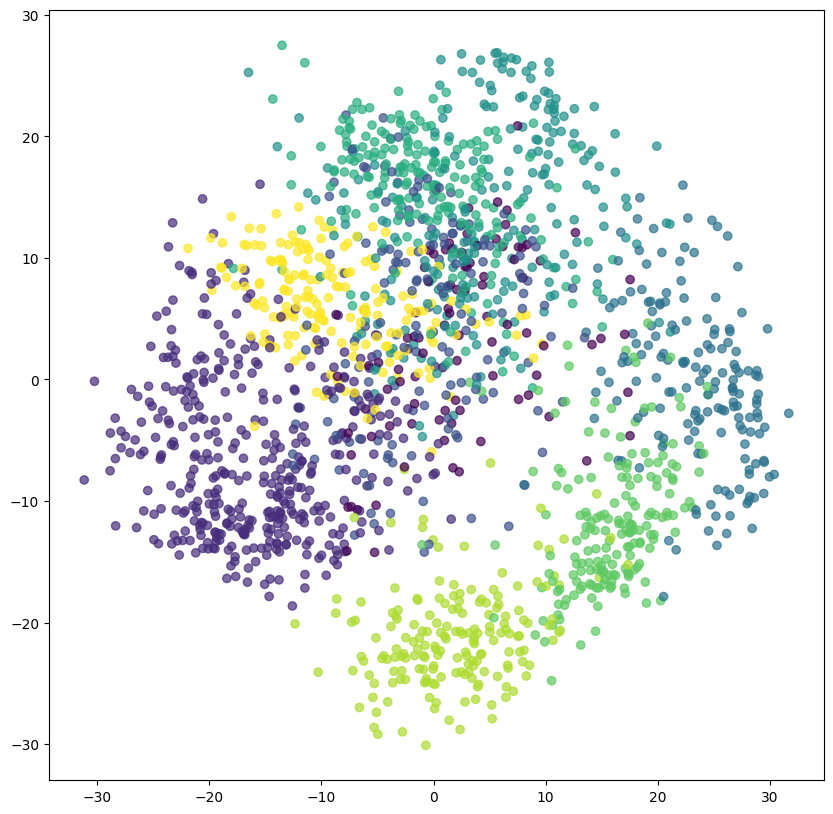

In [48]:
preds = KMeans(n_clusters=best_k).fit_predict(X)
plt.figure(figsize=(10, 10))
plt.scatter(new_X[:, 0], new_X[:, 1], c=preds, alpha=0.7)
plt.show()

#### **Задание 6**

Найдите наилучшее сочетание параметров `eps` и `min_samples` для DBSCAN.

Сколько кластеров получилось? (можно определить с помощью `set()`).

Визуализируйте результат.

In [49]:
best_score = -1
for eps in range(10, 31):
    for ms in range(2, 11):
        preds = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
        if len(set(preds)) < 2:
            continue
        score = silhouette_score(X, preds)
        if score > best_score:
            best_score = score
            best_eps, best_ms = eps, ms

print(best_eps, best_ms, best_score)

30 10 0.11419270968296504


2


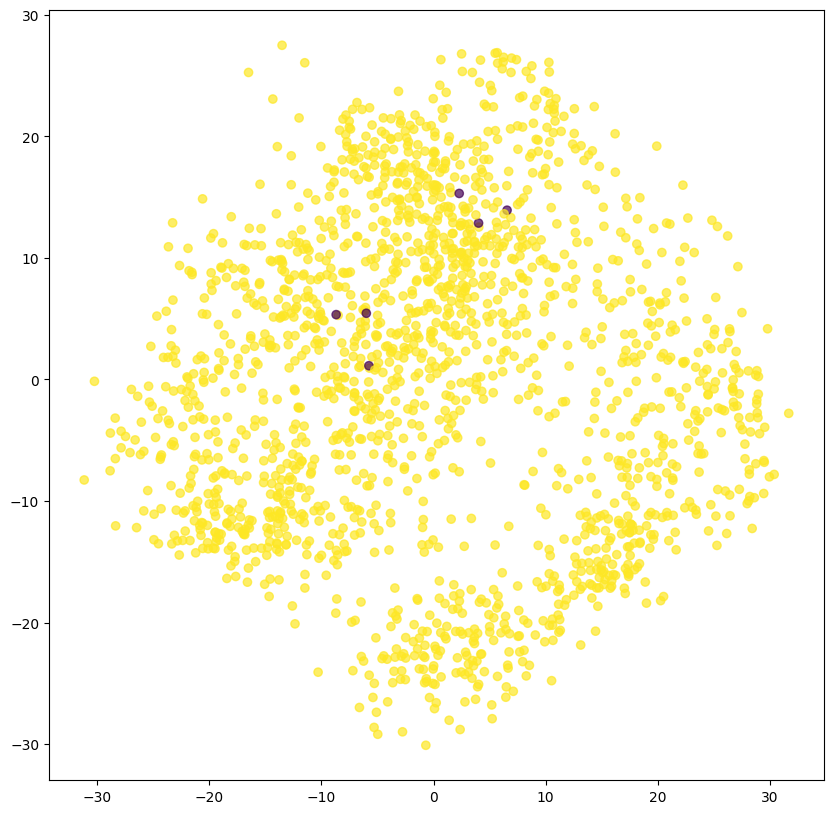

In [50]:
preds = DBSCAN(eps=best_eps, min_samples=best_ms).fit_predict(X)
print(len(set(preds)))

plt.figure(figsize=(10, 10))
plt.scatter(new_X[:, 0], new_X[:, 1], c=preds, alpha=0.7)
plt.show()

#### **Задание 7***

Сделаем предположение, что количество объектов в каждом кластере примерно одинаково.

Используя `Kmeans` или `DBSCAN`, проверьте это предположение.